
# Project 23: Agentic AI for Intelligent Business Process Automation

## Notebook 03 — Demand Forecasting & Model Evaluation

**Dataset:** Walmart M5 Forecasting Dataset  
**Store:** CA_1  
**Forecast Horizon:** 28 Days

### Objectives
1. Load and validate preprocessed datasets.
2. Establish a 28-day forecasting baseline.
3. Train LightGBM and XGBoost models.
4. Evaluate forecasting performance.
5. Compare models across product categories.
6. Select the best model for the AI agent.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

pd.set_option("display.max_columns", 30)

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Load and Validate Processed Datasets

In [2]:

# Processed data directory
data_dir = Path("../data/processed")

# Load training, validation, and test datasets
train = pd.read_parquet(data_dir / "train.parquet")
val = pd.read_parquet(data_dir / "validation.parquet")
test = pd.read_parquet(data_dir / "test.parquet")

# Check dataset dimensions
print("Training:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

# Verify date ranges
for name, df in [
    ("Training", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        f"{name}: {df['date'].min().date()} "
        f"to {df['date'].max().date()}"
    )


Training: (4364506, 19)
Validation: (85372, 19)
Test: (85372, 19)
Training: 2011-03-25 to 2016-02-28
Validation: 2016-02-29 to 2016-03-27
Test: 2016-03-28 to 2016-04-24


In [3]:

forecast_horizon = 28

validation_origin = pd.Timestamp("2016-02-28")
test_origin = pd.Timestamp("2016-03-27")

for name, df, origin in [
    ("Validation", val, validation_origin),
    ("Test", test, test_origin)
]:
    latest_source_date = (
        df["date"] - pd.Timedelta(days=28)
    ).max()

    print(f"\n{name}")
    print("Forecast origin:", origin.date())
    print("Latest historical source:",
          latest_source_date.date())

    assert latest_source_date <= origin

    print("Historical cutoff validation: PASSED")



Validation
Forecast origin: 2016-02-28
Latest historical source: 2016-02-28
Historical cutoff validation: PASSED

Test
Forecast origin: 2016-03-27
Latest historical source: 2016-03-27
Historical cutoff validation: PASSED


## 3. Seasonal Naive Baseline
### 3.1 Generate 28-Day Forecasts

In [4]:

# Load original sales data
sales_raw = pd.read_csv(
    "../data/sales_train_validation.csv"
)

# Select CA_1
sales_ca1 = sales_raw.loc[
    sales_raw["store_id"] == "CA_1"
].copy()

# Map each forecast date to a historical day column
calendar = pd.read_csv("../data/calendar.csv")
calendar["date"] = pd.to_datetime(calendar["date"])

date_to_day = calendar.set_index("date")["d"]

def seasonal_naive_forecast(df, origin):
    forecast_dates = pd.date_range(
        origin + pd.Timedelta(days=1),
        periods=28
    )

    # Repeat the last observed week
    source_dates = forecast_dates - pd.Timedelta(days=28)

    source_cols = date_to_day.loc[source_dates].tolist()

    historical = sales_ca1.set_index("item_id")[source_cols].copy()
    historical.columns = forecast_dates

    predictions = historical.stack().rename(
        "prediction"
    ).reset_index()

    predictions.columns = [
        "item_id", "date", "prediction"
    ]

    return predictions

val_baseline = seasonal_naive_forecast(
    val,
    pd.Timestamp("2016-02-28")
)

test_baseline = seasonal_naive_forecast(
    test,
    pd.Timestamp("2016-03-27")
)

print("Validation predictions:", val_baseline.shape)
print("Test predictions:", test_baseline.shape)

print("\nSample predictions:")
print(val_baseline.head())


Validation predictions: (85372, 3)
Test predictions: (85372, 3)

Sample predictions:
         item_id       date  prediction
0  HOBBIES_1_001 2016-02-29           1
1  HOBBIES_1_001 2016-03-01           1
2  HOBBIES_1_001 2016-03-02           1
3  HOBBIES_1_001 2016-03-03           1
4  HOBBIES_1_001 2016-03-04           0


### 3.2 Seasonal Naive Baseline Evaluation

In [5]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(actual_df, prediction_df):
    # Join predictions with actual observations
    results = actual_df[
        ["item_id", "date", "sales"]
    ].merge(
        prediction_df,
        on=["item_id", "date"],
        how="left",
        validate="one_to_one"
    )

    # Ensure every observation has a prediction
    assert results["prediction"].notna().all()
    assert len(results) == len(actual_df)

    y_true = results["sales"].to_numpy()
    y_pred = results["prediction"].to_numpy()

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    # Weighted Absolute Percentage Error
    total_actual = np.abs(y_true).sum()
    wape = (
        np.abs(y_true - y_pred).sum()
        / total_actual * 100
        if total_actual > 0 else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

# Evaluate validation forecasts
val_metrics = evaluate_forecast(
    val, val_baseline
)

# Keep test data untouched until final model evaluation

print("Seasonal Naive - Validation Results")
for metric, value in val_metrics.items():
    print(f"{metric}: {value:.4f}")


Seasonal Naive - Validation Results
MAE: 1.3339
RMSE: 2.9274
WAPE (%): 90.9251


## 4. LightGBM Demand Forecasting
### 4.1 Environment Verification

In [9]:

import sys

print("Jupyter Python:", sys.executable)


Jupyter Python: c:\Users\shwey\anaconda3\python.exe


In [10]:
%pip install lightgbm

  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.


In [11]:

import sys
import lightgbm as lgb

print("Python:", sys.executable)
print("LightGBM version:", lgb.__version__)
print("LightGBM installed successfully!")


Python: c:\Users\shwey\anaconda3\python.exe
LightGBM version: 4.7.0
LightGBM installed successfully!


### 4.2 Prepare Training and Validation Features

In [13]:

# Define modeling features
historical_features = [
    "lag_28",
    "lag_35",
    "rolling_mean_7",
    "rolling_mean_28"
]

calendar_features = [
    "day_of_week",
    "is_weekend",
    "day_of_month",
    "month",
    "quarter",
    "year",
    "is_event",
    "is_christmas",
    "snap_CA"
]

categorical_features = [
    "item_id",
    "dept_id",
    "cat_id"
]

feature_cols = (
    historical_features
    + calendar_features
    + categorical_features
)

# Separate features and targets
X_train = train[feature_cols].copy()
y_train = train["sales"].copy()

X_val = val[feature_cols].copy()
y_val = val["sales"].copy()

# Verify categorical feature types
for col in categorical_features:
    assert str(X_train[col].dtype) == "category"
    assert str(X_val[col].dtype) == "category"

# Verify dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nMissing training features:")
print(X_train.isna().sum().sum())

print("\nMissing validation features:")
print(X_val.isna().sum().sum())


X_train: (4364506, 16)
y_train: (4364506,)
X_val: (85372, 16)
y_val: (85372,)

Missing training features:
0

Missing validation features:
88


### 4.3 LightGBM Model Training

In [14]:

import lightgbm as lgb

# Initialize LightGBM regressor
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train using chronological validation data
lgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    categorical_feature=categorical_features,
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=30,
            verbose=True
        ),
        lgb.log_evaluation(period=50)
    ]
)

print("\nTraining completed!")
print("Best iteration:", lgb_model.best_iteration_)
print("Best validation RMSE:",
      lgb_model.best_score_["valid_0"]["rmse"])


c:\Users\shwey\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 30 rounds
[50]	valid_0's rmse: 2.22528	valid_0's l2: 4.95185
[100]	valid_0's rmse: 2.20355	valid_0's l2: 4.85564
[150]	valid_0's rmse: 2.20526	valid_0's l2: 4.86318
Early stopping, best iteration is:
[130]	valid_0's rmse: 2.2022	valid_0's l2: 4.84968

Training completed!
Best iteration: 130
Best validation RMSE: 2.2021986046316164


### 4.4 LightGBM Validation Evaluation

In [15]:

# Generate validation predictions
lgb_predictions = lgb_model.predict(
    X_val,
    num_iteration=lgb_model.best_iteration_
)

# Sales cannot be negative
lgb_predictions = np.maximum(lgb_predictions, 0)

# Prepare prediction DataFrame
lgb_val_predictions = val[
    ["item_id", "date"]
].copy()

lgb_val_predictions["prediction"] = lgb_predictions

# Evaluate using our existing function
lgb_metrics = evaluate_forecast(
    val,
    lgb_val_predictions
)

print("LightGBM - Validation Results")

for metric, value in lgb_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nSeasonal Naive - Validation Results")

for metric, value in val_metrics.items():
    print(f"{metric}: {value:.4f}")


LightGBM - Validation Results
MAE: 1.1335
RMSE: 2.2022
WAPE (%): 77.2655

Seasonal Naive - Validation Results
MAE: 1.3339
RMSE: 2.9274
WAPE (%): 90.9251


### 4.5 LightGBM Feature Importance Analysis

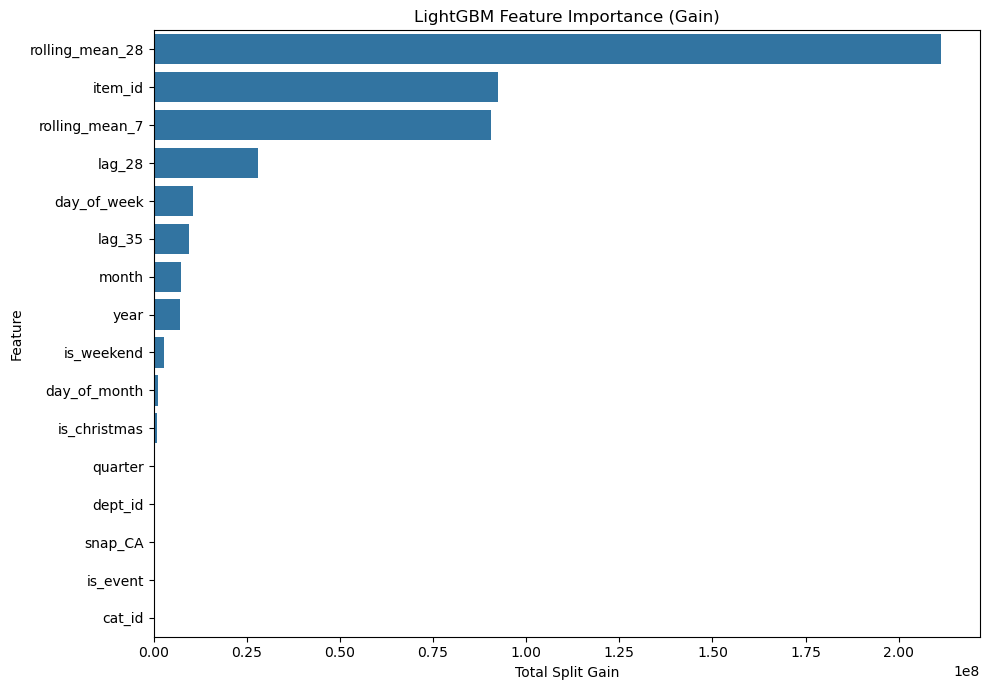

            feature    importance
3   rolling_mean_28  2.112455e+08
13          item_id  9.230790e+07
2    rolling_mean_7  9.045609e+07
0            lag_28  2.802907e+07
4       day_of_week  1.044997e+07
1            lag_35  9.414281e+06
7             month  7.268041e+06
9              year  6.986539e+06
5        is_weekend  2.672123e+06
6      day_of_month  1.202971e+06
11     is_christmas  8.104501e+05
8           quarter  4.396695e+05
14          dept_id  2.806592e+05
12          snap_CA  8.577592e+04
10         is_event  4.769708e+04
15           cat_id  1.116733e+04


In [16]:

# Extract feature importance using total gain
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgb_model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

# Visualize importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="importance",
    y="feature"
)

plt.title("LightGBM Feature Importance (Gain)")
plt.xlabel("Total Split Gain")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(importance_df)


## 5. XGBoost Demand Forecasting
### 5.1 Environment Verification

In [17]:

import xgboost as xgb

print("XGBoost version:", xgb.__version__)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))

print("\nCategorical features:")
print(X_train[categorical_features].dtypes)


XGBoost version: 3.1.3
Training observations: 4364506
Validation observations: 85372

Categorical features:
item_id    category
dept_id    category
cat_id     category
dtype: object


### 5.2 XGBoost Model Training

In [18]:

import xgboost as xgb

# Initialize XGBoost regressor
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="rmse",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

# Display training results
print("\nTraining completed!")
print("Best iteration:", xgb_model.best_iteration)
print("Best validation RMSE:", xgb_model.best_score)


[0]	validation_0-rmse:3.34068
[50]	validation_0-rmse:2.23238
[100]	validation_0-rmse:2.22263
[116]	validation_0-rmse:2.22495

Training completed!
Best iteration: 86
Best validation RMSE: 2.220471572473328


### 5.3 XGBoost Validation Evaluation

In [19]:

# Generate XGBoost predictions
xgb_predictions = xgb_model.predict(X_val)

# Ensure non-negative demand forecasts
xgb_predictions = np.maximum(xgb_predictions, 0)

# Prepare predictions
xgb_val_predictions = val[
    ["item_id", "date"]
].copy()

xgb_val_predictions["prediction"] = xgb_predictions

# Evaluate model
xgb_metrics = evaluate_forecast(
    val,
    xgb_val_predictions
)

print("XGBoost - Validation Results")
for metric, value in xgb_metrics.items():
    print(f"{metric}: {value:.4f}")


XGBoost - Validation Results
MAE: 1.1417
RMSE: 2.2205
WAPE (%): 77.8220


### 5.4 Category-Level Model Evaluation

In [20]:

# Combine actual sales with model predictions
category_results = val[
    ["item_id", "cat_id", "date", "sales"]
].copy()

# Predictions are aligned with val rows
category_results["LightGBM"] = lgb_predictions
category_results["XGBoost"] = xgb_predictions

# Add seasonal naive predictions by matching keys
category_results = category_results.merge(
    val_baseline.rename(
        columns={"prediction": "Seasonal Naive"}
    ),
    on=["item_id", "date"],
    how="left",
    validate="one_to_one"
)

assert category_results["Seasonal Naive"].notna().all()

# Calculate category-level performance
records = []

for category, group in category_results.groupby(
    "cat_id", observed=True
):
    actual = group["sales"].to_numpy()

    for model in ["Seasonal Naive", "LightGBM", "XGBoost"]:
        predicted = group[model].to_numpy()

        records.append({
            "Category": category,
            "Model": model,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "WAPE (%)": (
                np.abs(actual - predicted).sum()
                / actual.sum() * 100
                if actual.sum() > 0 else np.nan
            )
        })

category_metrics = pd.DataFrame(records)

print(category_metrics.round(4))


    Category           Model     MAE    RMSE  WAPE (%)
0      FOODS  Seasonal Naive  1.7377  3.5155   83.7616
1      FOODS        LightGBM  1.4690  2.7079   70.8084
2      FOODS         XGBoost  1.4862  2.7394   71.6378
3    HOBBIES  Seasonal Naive  1.1059  3.0110  123.7095
4    HOBBIES        LightGBM  0.9411  2.1430  105.2816
5    HOBBIES         XGBoost  0.9395  2.1383  105.0951
6  HOUSEHOLD  Seasonal Naive  0.9027  1.7610   95.7870
7  HOUSEHOLD        LightGBM  0.7769  1.2572   82.4343
8  HOUSEHOLD         XGBoost  0.7780  1.2616   82.5461


## 6. Forecasting Pipeline Validation
### 6.1 Historical Feature Alignment

In [21]:

# Examine one product's historical features
sample_item = "FOODS_1_001"

sample = (
    train.loc[
        train["item_id"] == sample_item,
        ["date", "sales", "lag_28", "lag_35",
         "rolling_mean_7", "rolling_mean_28"]
    ]
    .sort_values("date")
    .tail(10)
)

print(sample.to_string(index=False))

# Verify chronological separation
print("\nTraining end:", train["date"].max())
print("Validation start:", val["date"].min())
print("Test start:", test["date"].min())

assert train["date"].max() < val["date"].min()
assert val["date"].max() < test["date"].min()

print("\nChronological boundaries: PASSED")


      date  sales  lag_28  lag_35  rolling_mean_7  rolling_mean_28
2016-02-19      1     0.0     0.0        0.285714         0.392857
2016-02-20      2     0.0     0.0        0.285714         0.357143
2016-02-21      0     0.0     1.0        0.142857         0.357143
2016-02-22      0     0.0     0.0        0.142857         0.357143
2016-02-23      1     1.0     0.0        0.285714         0.392857
2016-02-24      0     1.0     0.0        0.428571         0.428571
2016-02-25      0     2.0     1.0        0.571429         0.428571
2016-02-26      0     1.0     0.0        0.714286         0.464286
2016-02-27      0     0.0     0.0        0.714286         0.464286
2016-02-28      0     2.0     0.0        1.000000         0.535714

Training end: 2016-02-28 00:00:00
Validation start: 2016-02-29 00:00:00
Test start: 2016-03-28 00:00:00

Chronological boundaries: PASSED


### 6.3 Verify Lag-28 Feature Accuracy

In [22]:

# Select one product
sample_item = "FOODS_1_001"

# Historical training records
sample_train = (
    train.loc[train["item_id"] == sample_item]
    .sort_values("date")
    .copy()
)

# Load the original product's daily sales
original_item = sales_ca1.loc[
    sales_ca1["item_id"] == sample_item
].iloc[0]

# Calendar mapping: date -> day identifier
calendar_lookup = calendar.set_index("date")["d"]

# Verify the final 10 training observations
check = sample_train.tail(10).copy()

check["source_date"] = (
    check["date"] - pd.Timedelta(days=28)
)

check["source_day"] = check["source_date"].map(
    calendar_lookup
)

check["actual_historical_sales"] = (
    check["source_day"].map(original_item)
)

check["lag_matches"] = (
    check["lag_28"]
    == check["actual_historical_sales"]
)

print(
    check[
        [
            "date",
            "source_date",
            "lag_28",
            "actual_historical_sales",
            "lag_matches"
        ]
    ].to_string(index=False)
)

assert check["lag_matches"].all()

print("\nLag-28 verification: PASSED")


      date source_date  lag_28 actual_historical_sales  lag_matches
2016-02-19  2016-01-22     0.0                       0         True
2016-02-20  2016-01-23     0.0                       0         True
2016-02-21  2016-01-24     0.0                       0         True
2016-02-22  2016-01-25     0.0                       0         True
2016-02-23  2016-01-26     1.0                       1         True
2016-02-24  2016-01-27     1.0                       1         True
2016-02-25  2016-01-28     2.0                       2         True
2016-02-26  2016-01-29     1.0                       1         True
2016-02-27  2016-01-30     0.0                       0         True
2016-02-28  2016-01-31     2.0                       2         True

Lag-28 verification: PASSED


### 6.4 Verify Rolling Feature Accuracy

In [23]:

# Select one product
sample_item = "FOODS_1_001"

sample_train = (
    train.loc[train["item_id"] == sample_item]
    .sort_values("date")
    .copy()
)

# Select the last training observation
row = sample_train.iloc[-1]
target_date = row["date"]

# Use the original sales history
original_item = sales_ca1.loc[
    sales_ca1["item_id"] == sample_item
].iloc[0]

calendar_lookup = calendar.set_index("date")["d"]

def historical_mean(target_date, window):
    end_date = target_date - pd.Timedelta(days=28)

    dates = pd.date_range(
        end=end_date,
        periods=window,
        freq="D"
    )

    day_ids = calendar_lookup.loc[dates].tolist()

    return float(
        original_item[day_ids].astype(float).mean()
    )

# Independently calculate rolling averages
expected_7 = historical_mean(target_date, 7)
expected_28 = historical_mean(target_date, 28)

print("Target date:", target_date.date())

print("\n7-day rolling mean")
print("Stored:", row["rolling_mean_7"])
print("Expected:", expected_7)

print("\n28-day rolling mean")
print("Stored:", row["rolling_mean_28"])
print("Expected:", expected_28)

# Validate results
assert np.isclose(row["rolling_mean_7"], expected_7)
assert np.isclose(row["rolling_mean_28"], expected_28)

print("\nRolling feature verification: PASSED")


Target date: 2016-02-28

7-day rolling mean
Stored: 1.0
Expected: 1.0

28-day rolling mean
Stored: 0.5357142857142857
Expected: 0.5357142857142857

Rolling feature verification: PASSED


### 6.5 Forecast Horizon Mapping

In [24]:

forecast_horizon = 28

# Validation forecast origin
origin = pd.Timestamp("2016-02-28")

# Create the 28 future target dates
horizon_df = pd.DataFrame({
    "horizon": np.arange(1, forecast_horizon + 1)
})

horizon_df["forecast_origin"] = origin

horizon_df["target_date"] = (
    origin
    + pd.to_timedelta(horizon_df["horizon"], unit="D")
)

# Most recent historical date available
horizon_df["last_known_date"] = origin

# Days between last observation and target
horizon_df["lead_time_days"] = (
    horizon_df["target_date"]
    - horizon_df["last_known_date"]
).dt.days

print(horizon_df.head(7).to_string(index=False))

print("\nFinal forecast horizon:")
print(horizon_df.tail(1).to_string(index=False))

assert horizon_df["horizon"].tolist() == list(range(1, 29))
assert (horizon_df["lead_time_days"] == horizon_df["horizon"]).all()

print("\nForecast horizon mapping: PASSED")


 horizon forecast_origin target_date last_known_date  lead_time_days
       1      2016-02-28  2016-02-29      2016-02-28               1
       2      2016-02-28  2016-03-01      2016-02-28               2
       3      2016-02-28  2016-03-02      2016-02-28               3
       4      2016-02-28  2016-03-03      2016-02-28               4
       5      2016-02-28  2016-03-04      2016-02-28               5
       6      2016-02-28  2016-03-05      2016-02-28               6
       7      2016-02-28  2016-03-06      2016-02-28               7

Final forecast horizon:
 horizon forecast_origin target_date last_known_date  lead_time_days
      28      2016-02-28  2016-03-27      2016-02-28              28

Forecast horizon mapping: PASSED


### 6.6 Horizon-Aware Historical Feature Mapping

In [25]:

# Use the horizon mapping from Step 6.5
horizon_features = horizon_df.copy()

# Historical observation dates relative to the forecast origin
horizon_features["lag_1_source"] = (
    horizon_features["forecast_origin"]
    - pd.Timedelta(days=1)
)

horizon_features["lag_7_source"] = (
    horizon_features["forecast_origin"]
    - pd.Timedelta(days=7)
)

horizon_features["lag_28_source"] = (
    horizon_features["forecast_origin"]
    - pd.Timedelta(days=28)
)

# Rolling feature window ending at the origin
horizon_features["rolling_7_start"] = (
    horizon_features["forecast_origin"]
    - pd.Timedelta(days=6)
)

horizon_features["rolling_7_end"] = (
    horizon_features["forecast_origin"]
)

# Verify all historical sources are available
historical_date_cols = [
    "lag_1_source",
    "lag_7_source",
    "lag_28_source",
    "rolling_7_start",
    "rolling_7_end"
]

for col in historical_date_cols:
    assert (
        horizon_features[col]
        <= horizon_features["forecast_origin"]
    ).all()

print(
    horizon_features[
        ["horizon", "target_date",
         "lag_1_source", "lag_7_source",
         "rolling_7_start", "rolling_7_end"]
    ].head(7).to_string(index=False)
)

print("\nHorizon-aware feature mapping: PASSED")


 horizon target_date lag_1_source lag_7_source rolling_7_start rolling_7_end
       1  2016-02-29   2016-02-27   2016-02-21      2016-02-22    2016-02-28
       2  2016-03-01   2016-02-27   2016-02-21      2016-02-22    2016-02-28
       3  2016-03-02   2016-02-27   2016-02-21      2016-02-22    2016-02-28
       4  2016-03-03   2016-02-27   2016-02-21      2016-02-22    2016-02-28
       5  2016-03-04   2016-02-27   2016-02-21      2016-02-22    2016-02-28
       6  2016-03-05   2016-02-27   2016-02-21      2016-02-22    2016-02-28
       7  2016-03-06   2016-02-27   2016-02-21      2016-02-22    2016-02-28

Horizon-aware feature mapping: PASSED


### 6.7 Construct a Sample Direct Multi-Horizon Dataset

In [26]:

# One product and one validation forecast origin
sample_item = "FOODS_1_001"
origin = pd.Timestamp("2016-02-28")

# Historical sales, including the forecast-origin day
history = (
    sales_ca1.loc[
        sales_ca1["item_id"] == sample_item
    ]
    .iloc[0]
)

calendar_lookup = calendar.set_index("date")["d"]

def get_sales_on_date(date):
    day_id = calendar_lookup.loc[date]
    return float(history[day_id])

# Historical features known at forecast origin
lag_1 = get_sales_on_date(origin)
lag_7 = get_sales_on_date(origin - pd.Timedelta(days=7))
lag_28 = get_sales_on_date(origin - pd.Timedelta(days=28))

last_7_dates = pd.date_range(end=origin, periods=7)
last_28_dates = pd.date_range(end=origin, periods=28)

rolling_mean_7 = np.mean([
    get_sales_on_date(d) for d in last_7_dates
])

rolling_mean_28 = np.mean([
    get_sales_on_date(d) for d in last_28_dates
])

# Create future-horizon examples
sample_horizon_data = pd.DataFrame({
    "item_id": sample_item,
    "forecast_origin": origin,
    "horizon": np.arange(1, 29)
})

sample_horizon_data["target_date"] = (
    origin
    + pd.to_timedelta(
        sample_horizon_data["horizon"],
        unit="D"
    )
)

sample_horizon_data["lag_1"] = lag_1
sample_horizon_data["lag_7"] = lag_7
sample_horizon_data["lag_28"] = lag_28
sample_horizon_data["rolling_mean_7"] = rolling_mean_7
sample_horizon_data["rolling_mean_28"] = rolling_mean_28

# Add known future calendar features
sample_horizon_data["day_of_week"] = (
    sample_horizon_data["target_date"].dt.dayofweek
)

# Add actual targets for offline training/evaluation
sample_horizon_data["sales"] = (
    sample_horizon_data["target_date"]
    .map(lambda d: get_sales_on_date(d))
)

print("Shape:", sample_horizon_data.shape)

print(
    sample_horizon_data[
        [
            "target_date",
            "horizon",
            "lag_1",
            "lag_7",
            "rolling_mean_7",
            "sales"
        ]
    ].head(10).to_string(index=False)
)


Shape: (28, 11)
target_date  horizon  lag_1  lag_7  rolling_mean_7  sales
 2016-02-29        1    0.0    0.0        0.142857    1.0
 2016-03-01        2    0.0    0.0        0.142857    0.0
 2016-03-02        3    0.0    0.0        0.142857    1.0
 2016-03-03        4    0.0    0.0        0.142857    0.0
 2016-03-04        5    0.0    0.0        0.142857    0.0
 2016-03-05        6    0.0    0.0        0.142857    2.0
 2016-03-06        7    0.0    0.0        0.142857    0.0
 2016-03-07        8    0.0    0.0        0.142857    0.0
 2016-03-08        9    0.0    0.0        0.142857    0.0
 2016-03-09       10    0.0    0.0        0.142857    0.0


### 6.8 Construct Horizon-Aware Forecasting Datasets

In [27]:

# Prepare chronological daily sales matrix
day_columns = sorted(
    [c for c in sales_ca1.columns if c.startswith("d_")],
    key=lambda x: int(x.split("_")[1])
)

sales_matrix = (
    sales_ca1
    .set_index("item_id")[day_columns]
    .astype("float32")
)

# Day identifier lookup
date_to_d = calendar.set_index("date")["d"]

def build_horizon_dataset(origin, horizon=28):
    origin = pd.Timestamp(origin)

    # Historical window ending at forecast origin
    history_dates = pd.date_range(
        end=origin,
        periods=28
    )

    future_dates = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=horizon
    )

    history_cols = date_to_d.loc[history_dates].tolist()
    future_cols = date_to_d.loc[future_dates].tolist()

    history_values = sales_matrix[history_cols].to_numpy()
    target_values = sales_matrix[future_cols].to_numpy()

    n_products = len(sales_matrix)

    # Create product-level historical features
    features = pd.DataFrame({
        "item_id": sales_matrix.index,
        "lag_1": history_values[:, -1],
        "lag_7": history_values[:, -8],
        "lag_28": history_values[:, 0],
        "rolling_mean_7": history_values[:, -7:].mean(axis=1),
        "rolling_mean_28": history_values.mean(axis=1)
    })

    # Repeat features across forecast horizons
    result = features.loc[
        features.index.repeat(horizon)
    ].reset_index(drop=True)

    result["forecast_origin"] = origin
    result["horizon"] = np.tile(
        np.arange(1, horizon + 1),
        n_products
    )

    result["target_date"] = np.tile(
        future_dates.to_numpy(),
        n_products
    )

    result["sales"] = target_values.reshape(-1)

    # Known future calendar information
    result["day_of_week"] = result["target_date"].dt.dayofweek
    result["month"] = result["target_date"].dt.month
    result["day_of_month"] = result["target_date"].dt.day

    return result

# Test with a historical origin
sample_origin = pd.Timestamp("2016-02-28")

horizon_data = build_horizon_dataset(sample_origin)

print("Dataset shape:", horizon_data.shape)
print("Unique products:", horizon_data["item_id"].nunique())
print("Unique horizons:", horizon_data["horizon"].nunique())

print("\nSample:")
print(horizon_data.head())


Dataset shape: (85372, 13)
Unique products: 3049
Unique horizons: 28

Sample:
         item_id  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28  \
0  HOBBIES_1_001    2.0    0.0     1.0        1.714286         1.035714   
1  HOBBIES_1_001    2.0    0.0     1.0        1.714286         1.035714   
2  HOBBIES_1_001    2.0    0.0     1.0        1.714286         1.035714   
3  HOBBIES_1_001    2.0    0.0     1.0        1.714286         1.035714   
4  HOBBIES_1_001    2.0    0.0     1.0        1.714286         1.035714   

  forecast_origin  horizon target_date  sales  day_of_week  month  \
0      2016-02-28        1  2016-02-29    0.0            0      2   
1      2016-02-28        2  2016-03-01    2.0            1      3   
2      2016-02-28        3  2016-03-02    0.0            2      3   
3      2016-02-28        4  2016-03-03    1.0            3      3   
4      2016-02-28        5  2016-03-04    1.0            4      3   

   day_of_month  
0            29  
1             1  
2 


### 6.9 Validate Horizon-Aware Feature Generation

This step validates the reusable forecasting dataset generator
against an independently constructed single-product example.

The validation compares lag features, rolling averages,
forecast horizons, target dates, and actual sales values.

Matching results provide evidence that the dataset generation
process is consistent and correctly aligned for the sampled
product and forecast origin.



### 6.9 Fix and Validate Historical Feature Alignment


In [29]:

def build_horizon_dataset(origin, horizon=28):
    origin = pd.Timestamp(origin)

    # Include today and the previous 28 days
    history_dates = pd.date_range(
        end=origin,
        periods=29
    )

    future_dates = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=horizon
    )

    history_cols = date_to_d.loc[history_dates].tolist()
    future_cols = date_to_d.loc[future_dates].tolist()

    history_values = sales_matrix[history_cols].to_numpy()
    target_values = sales_matrix[future_cols].to_numpy()

    n_products = len(sales_matrix)

    features = pd.DataFrame({
        "item_id": sales_matrix.index,
        "lag_1": history_values[:, -1],
        "lag_7": history_values[:, -8],
        "lag_28": history_values[:, 0],
        "rolling_mean_7": history_values[:, -7:].mean(axis=1),
        "rolling_mean_28": history_values[:, -28:].mean(axis=1)
    })

    result = features.loc[
        features.index.repeat(horizon)
    ].reset_index(drop=True)

    result["forecast_origin"] = origin

    result["horizon"] = np.tile(
        np.arange(1, horizon + 1),
        n_products
    )

    result["target_date"] = np.tile(
        future_dates.to_numpy(),
        n_products
    )

    result["sales"] = target_values.reshape(-1)

    result["day_of_week"] = result["target_date"].dt.dayofweek
    result["month"] = result["target_date"].dt.month
    result["day_of_month"] = result["target_date"].dt.day

    return result

# Rebuild the dataset with corrected features
horizon_data = build_horizon_dataset("2016-02-28")

print("Corrected dataset shape:", horizon_data.shape)


Corrected dataset shape: (85372, 13)


In [30]:

# Check corrected dataset against our earlier example
generated = (
    horizon_data[
        horizon_data["item_id"] == "FOODS_1_001"
    ]
    .sort_values("horizon")
    .reset_index(drop=True)
)

expected = (
    sample_horizon_data
    .sort_values("horizon")
    .reset_index(drop=True)
)

columns_to_check = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "sales"
]

for col in columns_to_check:
    matches = np.allclose(
        generated[col],
        expected[col]
    )
    print(f"{col}: {'PASSED' if matches else 'FAILED'}")

print("Date alignment:",
      "PASSED" if generated["target_date"].equals(
          expected["target_date"]
      ) else "FAILED")


lag_1: PASSED
lag_7: PASSED
lag_28: PASSED
rolling_mean_7: PASSED
rolling_mean_28: PASSED
sales: PASSED
Date alignment: PASSED



### 6.10 Generate Historical Training Windows


In [32]:

# Select three historical forecast origins
training_origins = pd.to_datetime([
    "2015-10-25",
    "2015-11-22",
    "2015-12-20"
])

# Generate forecasting examples
training_windows = []

for origin in training_origins:
    window = build_horizon_dataset(origin)
    training_windows.append(window)

# Combine all windows
horizon_train_sample = pd.concat(
    training_windows,
    ignore_index=True
)

# Check results
print("Training dataset shape:", horizon_train_sample.shape)

print("\nForecast origins:")
print(horizon_train_sample["forecast_origin"].unique())

print("\nProducts:", horizon_train_sample["item_id"].nunique())
print("Horizons:", horizon_train_sample["horizon"].nunique())

print("\nSample records:")
print(horizon_train_sample.head())


Training dataset shape: (256116, 13)

Forecast origins:
<DatetimeArray>
['2015-10-25 00:00:00', '2015-11-22 00:00:00', '2015-12-20 00:00:00']
Length: 3, dtype: datetime64[ns]

Products: 3049
Horizons: 28

Sample records:
         item_id  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28  \
0  HOBBIES_1_001    1.0    0.0     0.0        0.428571         0.642857   
1  HOBBIES_1_001    1.0    0.0     0.0        0.428571         0.642857   
2  HOBBIES_1_001    1.0    0.0     0.0        0.428571         0.642857   
3  HOBBIES_1_001    1.0    0.0     0.0        0.428571         0.642857   
4  HOBBIES_1_001    1.0    0.0     0.0        0.428571         0.642857   

  forecast_origin  horizon target_date  sales  day_of_week  month  \
0      2015-10-25        1  2015-10-26    1.0            0     10   
1      2015-10-25        2  2015-10-27    0.0            1     10   
2      2015-10-25        3  2015-10-28    1.0            2     10   
3      2015-10-25        4  2015-10-29    0.0       


### 6.11 Identify Eligible Products for Forecasting


In [35]:

# Load the original selling prices dataset
prices = pd.read_csv("../data/sell_prices.csv")

# Select store CA_1
prices_ca1 = prices[
    prices["store_id"] == "CA_1"
].copy()

print("Prices CA_1:", prices_ca1.shape)


Prices CA_1: (698412, 4)


### Calulate Product Eligbility

In [36]:

# Find the first price week for each product
first_price_weeks = (
    prices_ca1.groupby("item_id")["wm_yr_wk"]
    .min()
)

# Find the first calendar date for each week
week_start_dates = (
    calendar.groupby("wm_yr_wk")["date"]
    .min()
)

# Map each product to its first recorded price date
first_price_dates = first_price_weeks.map(
    week_start_dates
)

# Add first price date
horizon_train_sample["first_price_date"] = (
    horizon_train_sample["item_id"].map(first_price_dates)
)

# Earliest historical date needed
horizon_train_sample["history_start"] = (
    horizon_train_sample["forecast_origin"]
    - pd.Timedelta(days=28)
)

# Determine eligibility
horizon_train_sample["is_eligible"] = (
    horizon_train_sample["history_start"]
    >= horizon_train_sample["first_price_date"]
)

# Display results
print("Total observations:", len(horizon_train_sample))
print("Eligible observations:",
      horizon_train_sample["is_eligible"].sum())
print("Ineligible observations:",
      (~horizon_train_sample["is_eligible"]).sum())

print("\nEligibility by forecast origin:")
print(
    horizon_train_sample.groupby("forecast_origin")[
        "is_eligible"
    ].agg(["sum", "count"])
)


Total observations: 256116
Eligible observations: 255724
Ineligible observations: 392

Eligibility by forecast origin:
                   sum  count
forecast_origin              
2015-10-25       85204  85372
2015-11-22       85260  85372
2015-12-20       85260  85372



### 6.12 Filter Eligible Training Observations


In [37]:

# Keep observations with sufficient history
horizon_train_clean = horizon_train_sample.loc[
    horizon_train_sample["is_eligible"]
].copy()

# Remove temporary validation columns
horizon_train_clean = horizon_train_clean.drop(
    columns=[
        "first_price_date",
        "history_start",
        "is_eligible"
    ]
)

# Reset row index
horizon_train_clean = (
    horizon_train_clean.reset_index(drop=True)
)

# Verify results
print("Clean training shape:", horizon_train_clean.shape)

print(
    "Unique products:",
    horizon_train_clean["item_id"].nunique()
)

print(
    "Forecast origins:",
    horizon_train_clean["forecast_origin"].nunique()
)

print(
    "Missing values:",
    horizon_train_clean.isna().sum().sum()
)


Clean training shape: (255724, 13)
Unique products: 3045
Forecast origins: 3
Missing values: 0



### 6.13 Generate Historical Forecast Origins


In [39]:

import pandas as pd

# Create historical starting dates
start_origin = pd.Timestamp("2013-01-27")
end_origin = pd.Timestamp("2016-01-31")

# Generate a new starting date every 28 days
training_origins_full = pd.date_range(
    start=start_origin,
    end=end_origin,
    freq="28D"
)

# Ensure training targets end before validation
training_origins_full = training_origins_full[
    training_origins_full + pd.Timedelta(days=28)
    <= pd.Timestamp("2016-02-28")
]

print("Total forecast origins:", len(training_origins_full))
print("First origin:", training_origins_full.min().date())
print("Last origin:", training_origins_full.max().date())


Total forecast origins: 40
First origin: 2013-01-27
Last origin: 2016-01-24



### 6.14 Generate Full Horizon-Aware Training Dataset


In [40]:

training_parts = []

for origin in training_origins_full:

    # Create forecasting examples for this date
    window = build_horizon_dataset(origin)

    # Check when products first had prices
    history_start = origin - pd.Timedelta(days=28)

    eligible = (
        window["item_id"].map(first_price_dates)
        <= history_start
    )

    # Keep products with enough history
    window = window.loc[eligible].copy()

    training_parts.append(window)

# Combine all training examples
horizon_train_full = pd.concat(
    training_parts,
    ignore_index=True
)

# Check our results
print("Training shape:", horizon_train_full.shape)

print("Forecast origins:",
      horizon_train_full["forecast_origin"].nunique())

print("Unique products:",
      horizon_train_full["item_id"].nunique())

print("Missing values:",
      horizon_train_full.isna().sum().sum())

print("Last training target date:",
      horizon_train_full["target_date"].max().date())


Training shape: (3118220, 13)
Forecast origins: 40
Unique products: 3047
Missing values: 0
Last training target date: 2016-02-21



### 6.15 Validate Horizon-Aware Training Dataset


In [41]:

# Check sales values
print("Negative sales:",
      (horizon_train_full["sales"] < 0).sum())

# Check forecast horizons
print("Minimum horizon:",
      horizon_train_full["horizon"].min())

print("Maximum horizon:",
      horizon_train_full["horizon"].max())

# Check future dates are after forecast origins
invalid_dates = (
    horizon_train_full["target_date"]
    <= horizon_train_full["forecast_origin"]
).sum()

print("Invalid future dates:", invalid_dates)

# Check that training ends before validation
overlap = (
    horizon_train_full["target_date"]
    >= pd.Timestamp("2016-02-29")
).sum()

print("Training-validation date overlap:", overlap)

# Check duplicate product-origin-horizon combinations
duplicates = horizon_train_full.duplicated(
    subset=["item_id", "forecast_origin", "horizon"]
).sum()

print("Duplicate training examples:", duplicates)


Negative sales: 0
Minimum horizon: 1
Maximum horizon: 28
Invalid future dates: 0
Training-validation date overlap: 0
Duplicate training examples: 0



### 6.16 Prepare Features for Horizon-Aware LightGBM


In [42]:

# Select the information the AI can use
horizon_feature_cols = [
    "item_id",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "horizon",
    "day_of_week",
    "month",
    "day_of_month"
]

# Create training features
X_horizon_train = horizon_train_full[
    horizon_feature_cols
].copy()

# Create training answers
y_horizon_train = horizon_train_full["sales"].copy()

# Tell LightGBM that item_id is a category
X_horizon_train["item_id"] = (
    X_horizon_train["item_id"].astype("category")
)

# Check results
print("Training features:", X_horizon_train.shape)
print("Training target:", y_horizon_train.shape)

print("\nFeature names:")
print(X_horizon_train.columns.tolist())

print("\nMissing feature values:")
print(X_horizon_train.isna().sum().sum())

# Make sure answers aren't included in features
assert "sales" not in X_horizon_train.columns
print("\nTarget separation: PASSED")


Training features: (3118220, 10)
Training target: (3118220,)

Feature names:
['item_id', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'horizon', 'day_of_week', 'month', 'day_of_month']

Missing feature values:
0

Target separation: PASSED



### 6.17 Prepare Horizon-Aware Validation Dataset


In [43]:

# Generate validation examples
horizon_val = build_horizon_dataset(
    "2016-02-28"
)

# Separate features and actual sales
X_horizon_val = horizon_val[
    horizon_feature_cols
].copy()

y_horizon_val = horizon_val["sales"].copy()

# Use the same product categories as training
X_horizon_val["item_id"] = pd.Categorical(
    X_horizon_val["item_id"],
    categories=X_horizon_train["item_id"].cat.categories
)

# Verify the validation dataset
print("Validation features:", X_horizon_val.shape)
print("Validation target:", y_horizon_val.shape)

print(
    "Unseen product IDs:",
    X_horizon_val["item_id"].isna().sum()
)

print(
    "Missing numerical features:",
    X_horizon_val.drop(columns="item_id").isna().sum().sum()
)

print(
    "Validation start:",
    horizon_val["target_date"].min().date()
)

print(
    "Validation end:",
    horizon_val["target_date"].max().date()
)


Validation features: (85372, 10)
Validation target: (85372,)
Unseen product IDs: 56
Missing numerical features: 0
Validation start: 2016-02-29
Validation end: 2016-03-27



### 6.18 Investigate Unseen Products in Validation


In [44]:

# Identify validation products absent from training
known_products = set(
    horizon_train_full["item_id"].unique()
)

validation_products = set(
    horizon_val["item_id"].unique()
)

unseen_products = sorted(
    validation_products - known_products
)

print("Number of unseen products:", len(unseen_products))
print("Unseen product IDs:", unseen_products)

# Check how many validation rows belong to them
unseen_rows = horizon_val[
    horizon_val["item_id"].isin(unseen_products)
]

print("\nUnseen product observations:", len(unseen_rows))

print("\nSales summary:")
print(
    unseen_rows.groupby("item_id")["sales"]
    .agg(["count", "sum", "mean"])
)


Number of unseen products: 2
Unseen product IDs: ['FOODS_3_296', 'FOODS_3_595']

Unseen product observations: 56

Sales summary:
             count   sum      mean
item_id                           
FOODS_3_296     28  24.0  0.857143
FOODS_3_595     28  34.0  1.214286



### 6.19 Handle Unseen Product Categories


In [45]:

# Create a shared category list
known_categories = list(
    X_horizon_train["item_id"].cat.categories
)

# Add a category for unseen products
all_categories = known_categories + ["UNKNOWN_PRODUCT"]

# Update training categories
X_horizon_train["item_id"] = (
    X_horizon_train["item_id"]
    .cat.set_categories(all_categories)
)

# Update validation categories
X_horizon_val["item_id"] = (
    X_horizon_val["item_id"]
    .cat.set_categories(all_categories)
    .fillna("UNKNOWN_PRODUCT")
)

# Verify results
print(
    "Missing training product IDs:",
    X_horizon_train["item_id"].isna().sum()
)

print(
    "Missing validation product IDs:",
    X_horizon_val["item_id"].isna().sum()
)

print(
    "Unknown product observations:",
    (X_horizon_val["item_id"] == "UNKNOWN_PRODUCT").sum()
)

print(
    "Training examples labelled UNKNOWN_PRODUCT:",
    (X_horizon_train["item_id"] == "UNKNOWN_PRODUCT").sum()
)


Missing training product IDs: 0
Missing validation product IDs: 0
Unknown product observations: 56
Training examples labelled UNKNOWN_PRODUCT: 0



### 6.20 Train Horizon-Aware LightGBM Model


In [46]:

import lightgbm as lgb

# Create the improved LightGBM model
horizon_lgb = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=100,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train using historical examples
horizon_lgb.fit(
    X_horizon_train,
    y_horizon_train,
    eval_X=X_horizon_val,
    eval_y=y_horizon_val,
    eval_metric="rmse",
    categorical_feature=["item_id"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=30,
            verbose=True
        ),
        lgb.log_evaluation(period=50)
    ]
)

print("\nTraining completed!")
print("Best iteration:", horizon_lgb.best_iteration_)
print(
    "Best validation RMSE:",
    horizon_lgb.best_score_["valid_0"]["rmse"]
)


Training until validation scores don't improve for 30 rounds
[50]	valid_0's rmse: 2.14439	valid_0's l2: 4.59839
[100]	valid_0's rmse: 2.13873	valid_0's l2: 4.57418
Early stopping, best iteration is:
[83]	valid_0's rmse: 2.13633	valid_0's l2: 4.5639

Training completed!
Best iteration: 83
Best validation RMSE: 2.136328039679788



### 6.21 Evaluate Horizon-Aware LightGBM


In [47]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict validation sales
horizon_val_predictions = horizon_lgb.predict(
    X_horizon_val,
    num_iteration=horizon_lgb.best_iteration_
)

# Sales cannot be negative
horizon_val_predictions = np.clip(
    horizon_val_predictions, 0, None
)

# Calculate metrics
horizon_mae = mean_absolute_error(
    y_horizon_val, horizon_val_predictions
)

horizon_rmse = np.sqrt(
    mean_squared_error(
        y_horizon_val, horizon_val_predictions
    )
)

horizon_wape = (
    np.abs(y_horizon_val.to_numpy() - horizon_val_predictions).sum()
    / y_horizon_val.sum()
) * 100

print(f"MAE: {horizon_mae:.4f}")
print(f"RMSE: {horizon_rmse:.4f}")
print(f"WAPE: {horizon_wape:.4f}%")


MAE: 1.1085
RMSE: 2.1363
WAPE: 75.5615%



### 6.22 Evaluate Unseen Product Forecasts


In [48]:

# Create a copy of validation results
horizon_val_results = horizon_val.copy()

# Add the model predictions
horizon_val_results["predicted_sales"] = (
    horizon_val_predictions
)

# Keep only products unseen during training
unseen_results = horizon_val_results[
    horizon_val_results["item_id"].isin(unseen_products)
].copy()

# Calculate absolute prediction errors
unseen_results["absolute_error"] = np.abs(
    unseen_results["sales"]
    - unseen_results["predicted_sales"]
)

# Show results for each unseen product
unseen_summary = unseen_results.groupby(
    "item_id"
).agg(
    actual_sales=("sales", "sum"),
    predicted_sales=("predicted_sales", "sum"),
    mae=("absolute_error", "mean")
)

print(unseen_summary.round(4))

# Calculate overall unseen-product MAE
print(
    "\nOverall unseen-product MAE:",
    round(unseen_results["absolute_error"].mean(), 4)
)


             actual_sales  predicted_sales     mae
item_id                                           
FOODS_3_296          24.0          12.5389  0.7611
FOODS_3_595          34.0          12.9196  1.0679

Overall unseen-product MAE: 0.9145



### 6.23 Compare Unseen Products Against Seasonal Naive Baseline


In [49]:

# Historical sales for unseen products
origin_date = pd.Timestamp("2016-02-28")

last_7_dates = pd.date_range(
    end=origin_date,
    periods=7
)

last_7_cols = date_to_d.loc[last_7_dates].tolist()

# Repeat last week's sales for the next 4 weeks
for item in unseen_products:
    recent_sales = sales_matrix.loc[
        item, last_7_cols
    ].to_numpy()

    baseline_predictions = np.tile(recent_sales, 4)

    actual_sales = horizon_val_results.loc[
        horizon_val_results["item_id"] == item,
        "sales"
    ].to_numpy()

    baseline_mae = np.mean(
        np.abs(actual_sales - baseline_predictions)
    )

    model_mae = unseen_summary.loc[item, "mae"]

    print(f"\nProduct: {item}")
    print(f"Baseline MAE: {baseline_mae:.4f}")
    print(f"LightGBM MAE: {model_mae:.4f}")

    if model_mae < baseline_mae:
        print("Better method: LightGBM")
    elif model_mae > baseline_mae:
        print("Better method: Seasonal Naive")
    else:
        print("Both methods have equal MAE")



Product: FOODS_3_296
Baseline MAE: 0.7857
LightGBM MAE: 0.7611
Better method: LightGBM

Product: FOODS_3_595
Baseline MAE: 1.4286
LightGBM MAE: 1.0679
Better method: LightGBM



### 6.24 Evaluate Forecast Accuracy by Horizon


In [50]:

# Calculate prediction errors
horizon_val_results["absolute_error"] = np.abs(
    horizon_val_results["sales"]
    - horizon_val_results["predicted_sales"]
)

horizon_val_results["squared_error"] = (
    horizon_val_results["sales"]
    - horizon_val_results["predicted_sales"]
) ** 2

# Calculate MAE and RMSE for each future day
horizon_metrics = horizon_val_results.groupby(
    "horizon"
).agg(
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean")
)

horizon_metrics["RMSE"] = np.sqrt(
    horizon_metrics["MSE"]
)

horizon_metrics = horizon_metrics[
    ["MAE", "RMSE"]
]

print(horizon_metrics.round(4))


            MAE    RMSE
horizon                
1        0.9531  1.7004
2        0.9985  1.9488
3        0.9778  1.8648
4        0.9695  1.6959
5        1.0408  1.9713
6        1.2534  2.3748
7        1.4679  2.9766
8        1.0847  1.9949
9        1.0452  1.9500
10       0.9962  1.9058
11       1.0229  1.9752
12       1.0687  2.0623
13       1.3195  2.6623
14       1.2778  2.4726
15       1.0479  1.8240
16       0.9320  1.5990
17       0.9772  1.7590
18       0.9339  1.6392
19       1.0594  1.8666
20       1.2925  2.3476
21       1.3705  3.0779
22       1.0905  1.9969
23       1.0175  1.9449
24       1.0045  1.9025
25       1.0309  1.9946
26       1.1878  2.1115
27       1.3959  2.8816
28       1.2224  2.3079



### 6.25 Compare Weekday and Weekend Forecast Accuracy


In [51]:

# Identify weekends using the target date
horizon_val_results["day_type"] = np.where(
    horizon_val_results["target_date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

# Calculate prediction errors by day type
day_type_metrics = horizon_val_results.groupby(
    "day_type"
).agg(
    observations=("sales", "size"),
    actual_sales=("sales", "sum"),
    predicted_sales=("predicted_sales", "sum"),
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean")
)

day_type_metrics["RMSE"] = np.sqrt(
    day_type_metrics["MSE"]
)

day_type_metrics["WAPE"] = (
    horizon_val_results.groupby("day_type")["absolute_error"].sum()
    / day_type_metrics["actual_sales"]
    * 100
)

print(
    day_type_metrics[
        ["observations", "MAE", "RMSE", "WAPE"]
    ].round(4)
)


          observations    MAE    RMSE     WAPE
day_type                                      
Weekday          60980  1.022  1.8904  79.1414
Weekend          24392  1.325  2.6532  69.4997



### 6.26 Analyze Weekday and Weekend Forecast Bias


In [52]:

# Compare actual and predicted total sales
bias_summary = horizon_val_results.groupby(
    "day_type"
).agg(
    actual_sales=("sales", "sum"),
    predicted_sales=("predicted_sales", "sum")
)

# Calculate forecast bias
bias_summary["bias"] = (
    bias_summary["predicted_sales"]
    - bias_summary["actual_sales"]
)

# Calculate percentage bias
bias_summary["bias_percent"] = (
    bias_summary["bias"]
    / bias_summary["actual_sales"]
    * 100
)

print(bias_summary.round(2))


          actual_sales  predicted_sales     bias  bias_percent
day_type                                                      
Weekday        78744.0         81301.00  2557.00          3.25
Weekend        46502.0         43558.17 -2943.83         -6.33



### 6.27 Analyze Forecast Bias by Product Category


In [53]:

# Match each product with its category
product_categories = (
    sales_ca1[["item_id", "cat_id"]]
    .drop_duplicates(subset="item_id")
)

category_results = horizon_val_results.merge(
    product_categories,
    on="item_id",
    how="left",
    validate="many_to_one"
)

# Calculate actual and predicted sales by category and day type
category_bias = category_results.groupby(
    ["cat_id", "day_type"]
).agg(
    actual_sales=("sales", "sum"),
    predicted_sales=("predicted_sales", "sum")
)

# Calculate percentage bias
category_bias["bias_percent"] = (
    (
        category_bias["predicted_sales"]
        - category_bias["actual_sales"]
    )
    / category_bias["actual_sales"]
    * 100
)

print(category_bias.round(2))


                    actual_sales  predicted_sales  bias_percent
cat_id    day_type                                             
FOODS     Weekday        52428.0         52242.70         -0.35
          Weekend        31047.0         28336.06         -8.73
HOBBIES   Weekday         9296.0         10600.91         14.04
          Weekend         4846.0          5357.54         10.56
HOUSEHOLD Weekday        17020.0         18457.40          8.45
          Weekend        10609.0          9864.56         -7.02



### 6.28 Evaluate Forecast Accuracy by Product Category


In [54]:

# Calculate accuracy for each product category
category_accuracy = category_results.groupby(
    "cat_id"
).agg(
    observations=("sales", "size"),
    actual_sales=("sales", "sum"),
    absolute_error=("absolute_error", "sum"),
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean")
)

# Calculate RMSE
category_accuracy["RMSE"] = np.sqrt(
    category_accuracy["MSE"]
)

# Calculate WAPE
category_accuracy["WAPE"] = (
    category_accuracy["absolute_error"]
    / category_accuracy["actual_sales"]
    * 100
)

print(
    category_accuracy[
        ["observations", "MAE", "RMSE", "WAPE"]
    ].round(4)
)


           observations     MAE    RMSE      WAPE
cat_id                                           
FOODS             40236  1.4177  2.5996   68.3337
HOBBIES           15820  0.9506  2.1508  106.3399
HOUSEHOLD         29316  0.7695  1.2326   81.6449



### 6.29 Summarize Validation Model Performance


In [55]:

import pandas as pd

validation_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Previous XGBoost",
        "Previous LightGBM",
        "Horizon-Aware LightGBM"
    ],
    "MAE": [
        1.3339,
        1.1417,
        1.1335,
        horizon_mae
    ],
    "RMSE": [
        2.9274,
        2.2205,
        2.2022,
        horizon_rmse
    ],
    "WAPE": [
        90.9251,
        77.8220,
        77.2655,
        horizon_wape
    ]
})

validation_comparison = (
    validation_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print(validation_comparison.round(4))

print(
    "\nLowest validation RMSE:",
    validation_comparison.loc[0, "Model"]
)


                    Model     MAE    RMSE     WAPE
0  Horizon-Aware LightGBM  1.1085  2.1363  75.5615
1       Previous LightGBM  1.1335  2.2022  77.2655
2        Previous XGBoost  1.1417  2.2205  77.8220
3          Seasonal Naive  1.3339  2.9274  90.9251

Lowest validation RMSE: Horizon-Aware LightGBM



### 6.30 Verify Validation Evaluation Population


In [56]:

# Check the new model's validation observations
print("New model observations:", len(horizon_val))

print(
    "New model unique products:",
    horizon_val["item_id"].nunique()
)

print(
    "New model unique dates:",
    horizon_val["target_date"].nunique()
)

# Check the original validation dataset
print("\nOriginal validation observations:", len(val))

print(
    "Original validation unique products:",
    val["item_id"].nunique()
)

print(
    "Original validation unique dates:",
    val["date"].nunique()
)

# Compare product-date pairs
new_pairs = set(
    zip(
        horizon_val["item_id"],
        horizon_val["target_date"]
    )
)

old_pairs = set(
    zip(
        val["item_id"],
        val["date"]
    )
)

print("\nIdentical product-date pairs:", new_pairs == old_pairs)

print("Only in new model:", len(new_pairs - old_pairs))
print("Only in old model:", len(old_pairs - new_pairs))


New model observations: 85372
New model unique products: 3049
New model unique dates: 28

Original validation observations: 85372
Original validation unique products: 3049
Original validation unique dates: 28

Identical product-date pairs: True
Only in new model: 0
Only in old model: 0



### 6.31 Prepare Final Horizon-Aware Test Dataset


In [57]:

# Generate 28-day test examples
horizon_test = build_horizon_dataset(
    "2016-03-27"
)

# Separate features and real sales
X_horizon_test = horizon_test[
    horizon_feature_cols
].copy()

y_horizon_test = horizon_test["sales"].copy()

# Use the same product categories as training
X_horizon_test["item_id"] = pd.Categorical(
    X_horizon_test["item_id"],
    categories=X_horizon_train["item_id"].cat.categories
)

# Replace unseen product IDs
X_horizon_test["item_id"] = (
    X_horizon_test["item_id"]
    .fillna("UNKNOWN_PRODUCT")
)

# Verify test dataset
print("Test features:", X_horizon_test.shape)
print("Test target:", y_horizon_test.shape)

print(
    "Unknown product observations:",
    (X_horizon_test["item_id"] == "UNKNOWN_PRODUCT").sum()
)

print(
    "Missing values:",
    X_horizon_test.isna().sum().sum()
)

print(
    "Test period:",
    horizon_test["target_date"].min().date(),
    "to",
    horizon_test["target_date"].max().date()
)


Test features: (85372, 10)
Test target: (85372,)
Unknown product observations: 56
Missing values: 0
Test period: 2016-03-28 to 2016-04-24



### 6.32 Evaluate Horizon-Aware LightGBM on Final Test Data


In [58]:

# Generate predictions using our selected model
horizon_test_predictions = horizon_lgb.predict(
    X_horizon_test,
    num_iteration=horizon_lgb.best_iteration_
)

# Product sales cannot be negative
horizon_test_predictions = np.clip(
    horizon_test_predictions, 0, None
)

# Calculate final test metrics
horizon_test_mae = mean_absolute_error(
    y_horizon_test,
    horizon_test_predictions
)

horizon_test_rmse = np.sqrt(
    mean_squared_error(
        y_horizon_test,
        horizon_test_predictions
    )
)

horizon_test_wape = (
    np.abs(
        y_horizon_test.to_numpy()
        - horizon_test_predictions
    ).sum()
    / y_horizon_test.sum()
) * 100

# Display results
print("FINAL TEST RESULTS")
print(f"MAE: {horizon_test_mae:.4f}")
print(f"RMSE: {horizon_test_rmse:.4f}")
print(f"WAPE: {horizon_test_wape:.4f}%")

print("\nVALIDATION RESULTS")
print(f"MAE: {horizon_mae:.4f}")
print(f"RMSE: {horizon_rmse:.4f}")
print(f"WAPE: {horizon_wape:.4f}%")


FINAL TEST RESULTS
MAE: 1.1151
RMSE: 2.1743
WAPE: 74.3993%

VALIDATION RESULTS
MAE: 1.1085
RMSE: 2.1363
WAPE: 75.5615%



### 6.33 Save Final Horizon-Aware LightGBM Model


In [59]:

import joblib
from pathlib import Path

# Create model directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save trained model and feature list
model_path = model_dir / "horizon_lightgbm.pkl"

joblib.dump(
    {
        "model": horizon_lgb,
        "feature_columns": horizon_feature_cols,
        "validation_metrics": {
            "MAE": horizon_mae,
            "RMSE": horizon_rmse,
            "WAPE": horizon_wape
        },
        "test_metrics": {
            "MAE": horizon_test_mae,
            "RMSE": horizon_test_rmse,
            "WAPE": horizon_test_wape
        }
    },
    model_path
)

print("Model saved successfully!")
print("Location:", model_path.resolve())
print("File size (MB):",
      round(model_path.stat().st_size / (1024**2), 2))


Model saved successfully!
Location: C:\Projects\23_Agentic_Business_AI\models\horizon_lightgbm.pkl
File size (MB): 0.51



### 6.34 Verify Saved LightGBM Model


In [60]:

# Load the saved model
saved_package = joblib.load(model_path)

loaded_model = saved_package["model"]
loaded_features = saved_package["feature_columns"]

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(
    X_horizon_test[loaded_features],
    num_iteration=loaded_model.best_iteration_
)

loaded_predictions = np.clip(
    loaded_predictions, 0, None
)

# Compare with original predictions
predictions_match = np.allclose(
    horizon_test_predictions,
    loaded_predictions
)

print("Model loaded successfully!")
print("Features:", len(loaded_features))
print("Predictions match:", predictions_match)

assert predictions_match, "Saved model predictions do not match!"

print("Model verification: PASSED")


Model loaded successfully!
Features: 10
Predictions match: True
Model verification: PASSED



### 6.35 Export Final Forecasting Model Summary


In [61]:

import json

model_summary = {
    "project": "Agentic AI for Intelligent Business System",
    "model": "Horizon-Aware LightGBM",
    "store": "CA_1",
    "forecast_horizon_days": 28,
    "training_origins": 40,
    "training_observations": len(X_horizon_train),
    "features": horizon_feature_cols,
    "best_iteration": int(horizon_lgb.best_iteration_),
    "validation": {
        "MAE": round(horizon_mae, 4),
        "RMSE": round(horizon_rmse, 4),
        "WAPE": round(horizon_wape, 4)
    },
    "test": {
        "MAE": round(horizon_test_mae, 4),
        "RMSE": round(horizon_test_rmse, 4),
        "WAPE": round(horizon_test_wape, 4)
    }
}

summary_path = model_dir / "horizon_model_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(model_summary, f, indent=4)

print("Model summary saved!")
print("Location:", summary_path.resolve())
print("\nFinal test RMSE:", model_summary["test"]["RMSE"])


Model summary saved!
Location: C:\Projects\23_Agentic_Business_AI\models\horizon_model_summary.json

Final test RMSE: 2.1743



# Inventory Planning and Replenishment Recommendations

## Conclusion

Developed and evaluated a 28-day demand forecasting system using Seasonal Naive, XGBoost, and LightGBM models.

The Horizon-Aware LightGBM achieved the best validation performance and was selected for final testing.

### Final Test Performance
- **MAE:** 1.1151
- **RMSE:** 2.1743
- **WAPE:** 74.40%

The model demonstrated similar performance across validation and test periods. Further analysis identified demand underestimation in certain categories and on weekends, highlighting limitations for inventory decisions.

The trained model and performance summary were successfully saved and verified.

**Next:** Integrate demand forecasts into an inventory replenishment system with human approval.

